<a href="https://colab.research.google.com/github/Gabrie1Tk/ProjetoFinal-ProcessamentoImagens/blob/main/Projeto_Final_Classico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Final – Processamento de Imagens
## Classificação do nível de torra de grãos de café com GLCM (Haralick) + Filtros de Gabor + Momentos de Cor

**Abordagem:** Clássica (extração de características + classificador tradicional).

**Dataset:** [Coffee Bean Dataset (resized 224x224) – Kaggle](https://www.kaggle.com/datasets/gpiosenka/coffee-bean-dataset-resized-224-x-224)
— 4 classes: `Dark`, `Green`, `Light`, `Medium`.

| Descritor | O que mede | Nº de características |
|---|---|---|
| **GLCM / Haralick** (matriz de co-ocorrência de níveis de cinza) | textura estatística de 2ª ordem: contraste, dissimilaridade, homogeneidade, energia, correlação, ASM e entropia | 42 |
| **Banco de filtros de Gabor** (3 escalas × 4 orientações) | textura em frequência/orientação (energia local da resposta do filtro) | 24 |
| **Momentos de cor** (Stricker & Orengo) nos espaços Lab e HSV | média, desvio padrão e assimetria de cada canal (tom da torra) | 15 |

**Classificadores:** SVM (kernel RBF) e Random Forest, com ajuste de hiperparâmetros por `GridSearchCV` (validação cruzada estratificada de 5 folds no treino).

**Avaliação:** conjunto `test` original (nunca usado no treino) → **matriz de confusão, precisão, recall, F1-score e acurácia**.

> Não precisa de GPU: o ambiente de execução padrão (CPU) do Colab é suficiente.

## 1. Bibliotecas e configurações

In [1]:
import os, json, time, random, pathlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import skimage
from skimage.feature import graycomatrix, graycoprops
from tqdm.auto import tqdm
import sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

print("OpenCV:", cv2.__version__, "| scikit-image:", skimage.__version__, "| scikit-learn:", sklearn.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

OpenCV: 5.0.0 | scikit-image: 0.25.2 | scikit-learn: 1.6.1


In [2]:
# ===================== PARÂMETROS =====================
IMG_SIZE  = (224, 224)
DATA_DIR  = None

GLCM_NIVEIS       = 32
GLCM_DISTANCIAS   = [1, 2, 4]
GLCM_ANGULOS      = [0, np.pi/4, np.pi/2, 3*np.pi/4]
GLCM_PROPRIEDADES = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

GABOR_ORIENTACOES       = 4
GABOR_COMPRIMENTOS_ONDA = [4, 8, 16]
GABOR_GAMMA             = 0.5

CV_FOLDS = 5

## 2. Download do dataset
O `kagglehub` baixa datasets públicos do Kaggle sem precisar de chave de API.
Se preferir, faça upload da pasta no Google Drive e informe o caminho em `DATA_DIR`.

In [3]:
if DATA_DIR is None:
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    DATA_DIR = kagglehub.dataset_download("gpiosenka/coffee-bean-dataset-resized-224-x-224")
print("Dataset em:", DATA_DIR)

def achar_pasta(raiz, nome):
    for p in sorted(pathlib.Path(raiz).rglob("*")):
        if p.is_dir() and p.name.lower() == nome and any(q.is_dir() for q in p.iterdir()):
            return str(p)
    raise FileNotFoundError(f"Pasta '{nome}' não encontrada em {raiz}")

TRAIN_DIR = achar_pasta(DATA_DIR, "train")
TEST_DIR  = achar_pasta(DATA_DIR, "test")
print("Treino:", TRAIN_DIR)
print("Teste :", TEST_DIR)

Using Colab cache for faster access to the 'coffee-bean-dataset-resized-224-x-224' dataset.
Dataset em: /kaggle/input/coffee-bean-dataset-resized-224-x-224
Treino: /kaggle/input/coffee-bean-dataset-resized-224-x-224/train
Teste : /kaggle/input/coffee-bean-dataset-resized-224-x-224/test


## 3. Análise exploratória

,treino,teste
Dark,300,100
Green,300,100
Light,300,100
Medium,300,100
TOTAL,1200,400


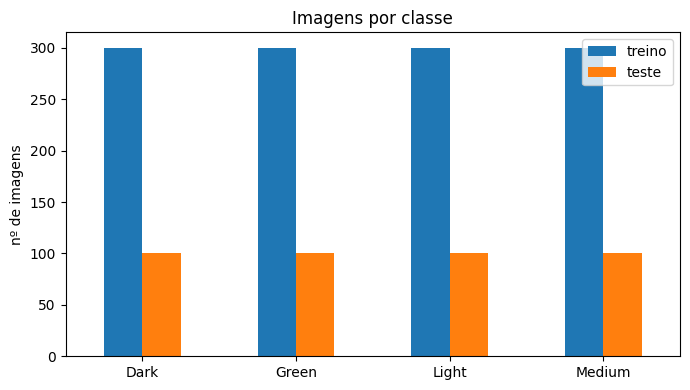

In [4]:
EXT = (".png", ".jpg", ".jpeg", ".bmp")
def contar(pasta):
    return {c: len([f for f in os.listdir(os.path.join(pasta, c)) if f.lower().endswith(EXT)])
            for c in sorted(os.listdir(pasta)) if os.path.isdir(os.path.join(pasta, c))}

contagem = pd.DataFrame({"treino": contar(TRAIN_DIR), "teste": contar(TEST_DIR)})
contagem.loc["TOTAL"] = contagem.sum()
display(contagem)

contagem.drop("TOTAL").plot(kind="bar", figsize=(7, 4), rot=0, title="Imagens por classe")
plt.ylabel("nº de imagens"); plt.tight_layout(); plt.show()

## 4. Carregamento das imagens
Adaptado do módulo `utils/dados.py` da aula (leitura com OpenCV e conversão BGR → RGB; o nome da subpasta é o rótulo).
Rótulos codificados com `LabelEncoder`, como em `utils/rotulos.py`.

Carregando train:   0%|          | 0/1200 [00:00<?, ?it/s]

Carregando test:   0%|          | 0/400 [00:00<?, ?it/s]

Classes: [np.str_('Dark'), np.str_('Green'), np.str_('Light'), np.str_('Medium')]
Treino: 1200 imagens | Teste: 400 imagens


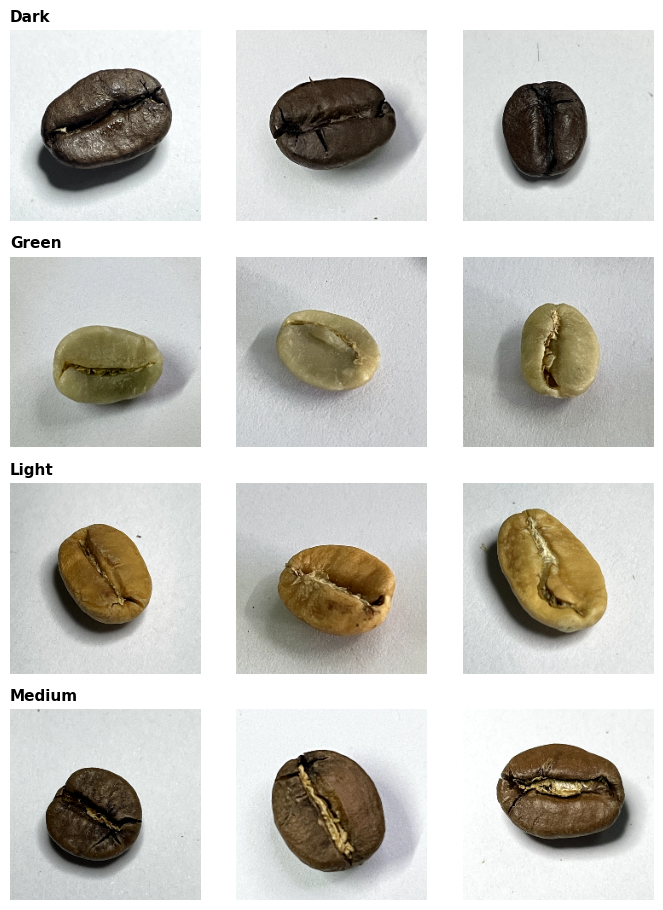

In [5]:
def ler_imagem(caminho):
    img = cv2.imread(caminho, cv2.IMREAD_COLOR)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if img.shape[:2] != (IMG_SIZE[1], IMG_SIZE[0]):
        img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    return img

def carregar_imagens(diretorio):
    classes = sorted(c for c in os.listdir(diretorio) if os.path.isdir(os.path.join(diretorio, c)))
    arquivos = [(c, os.path.join(diretorio, c, f)) for c in classes
                for f in sorted(os.listdir(os.path.join(diretorio, c))) if f.lower().endswith(EXT)]
    imagens, rotulos = [], []
    for c, caminho in tqdm(arquivos, desc=f"Carregando {os.path.basename(diretorio)}"):
        img = ler_imagem(caminho)
        if img is not None:
            imagens.append(img); rotulos.append(c)
    return imagens, rotulos

imagens_treino, rotulos_treino = carregar_imagens(TRAIN_DIR)
imagens_teste,  rotulos_teste  = carregar_imagens(TEST_DIR)

encoder = LabelEncoder().fit(rotulos_treino)
y_treino = encoder.transform(rotulos_treino)
y_teste  = encoder.transform(rotulos_teste)
CLASSES  = list(encoder.classes_)
print("Classes:", CLASSES)
print(f"Treino: {len(imagens_treino)} imagens | Teste: {len(imagens_teste)} imagens")

fig, ax = plt.subplots(len(CLASSES), 3, figsize=(7, 2.3 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    idx = np.where(y_treino == i)[0]
    for j, k in enumerate(np.random.choice(idx, 3, replace=False)):
        ax[i, j].imshow(imagens_treino[k]); ax[i, j].axis("off")
    ax[i, 0].set_title(c, loc="left", fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

## 5. Descritor 1 – GLCM / características de Haralick
A **GLCM** (*Gray-Level Co-occurrence Matrix*) conta com que frequência um par de níveis de cinza `(i, j)`
aparece separado por uma distância `d` numa direção `θ`. Dela se extraem estatísticas de textura (Haralick, 1973):

- **contraste**, **dissimilaridade**: variação local de intensidade;
- **homogeneidade**, **energia**, **ASM**: uniformidade da textura;
- **correlação**: dependência linear entre os níveis de cinza vizinhos;
- **entropia**: aleatoriedade da textura (calculada manualmente a partir da matriz).

Para cada distância (1, 2 e 4 px) calcula-se a **média nos 4 ângulos** (invariância à rotação, já que os grãos aparecem em
qualquer orientação) e a **amplitude entre os ângulos** (grau de direcionalidade). Total: 7 propriedades × 3 distâncias × 2 = **42 características**.

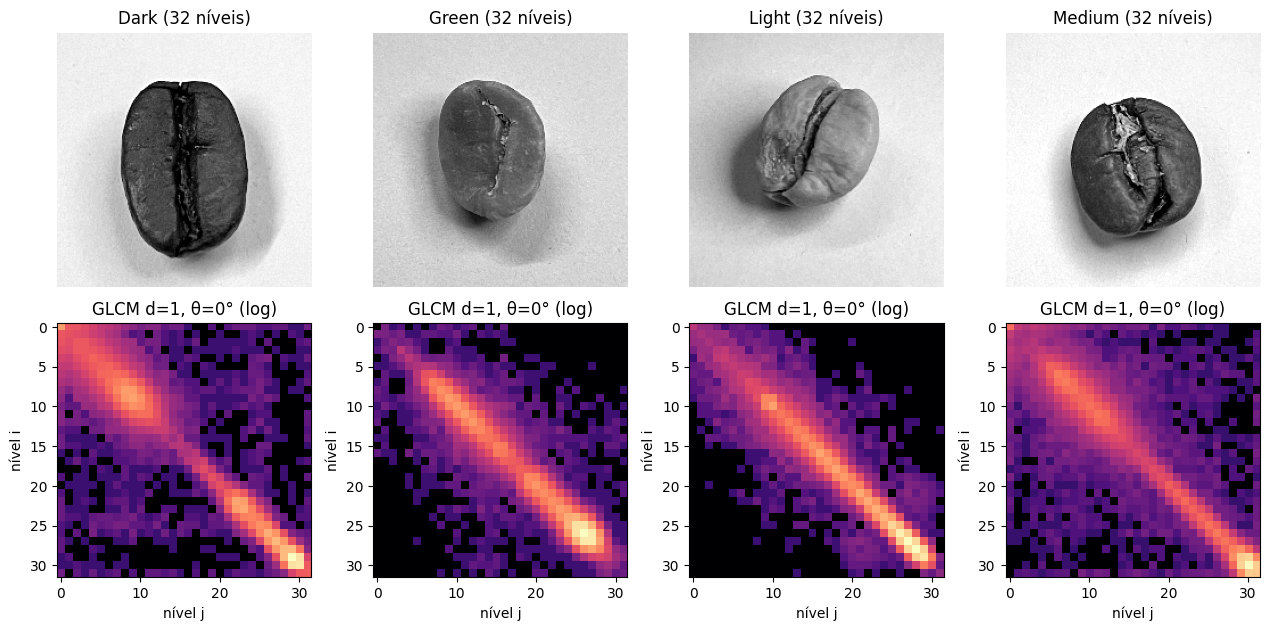

Nº de características GLCM: 42


In [6]:
def quantizar(img_cinza, niveis=GLCM_NIVEIS):
    return (img_cinza.astype(np.uint16) * niveis // 256).astype(np.uint8)

def extrair_glcm(img_cinza):
    q = quantizar(img_cinza)
    glcm = graycomatrix(q, distances=GLCM_DISTANCIAS, angles=GLCM_ANGULOS,
                        levels=GLCM_NIVEIS, symmetric=True, normed=True)
    feats = []
    for prop in GLCM_PROPRIEDADES:
        v = graycoprops(glcm, prop)
        feats.extend(v.mean(axis=1))
        feats.extend(np.ptp(v, axis=1))
    entropia = -np.sum(glcm * np.log2(glcm + 1e-12), axis=(0, 1))
    feats.extend(entropia.mean(axis=1))
    feats.extend(np.ptp(entropia, axis=1))
    return np.array(feats, dtype=np.float32)

NOMES_GLCM = [f"GLCM {p} d={d} {estat}"
              for p in GLCM_PROPRIEDADES + ["entropia"]
              for estat in ["média", "amplitude"]
              for d in GLCM_DISTANCIAS]

fig, ax = plt.subplots(2, len(CLASSES), figsize=(3.2 * len(CLASSES), 6.4))
for i, c in enumerate(CLASSES):
    k = np.where(y_treino == i)[0][0]
    cinza = cv2.cvtColor(imagens_treino[k], cv2.COLOR_RGB2GRAY)
    g = graycomatrix(quantizar(cinza), [1], [0], levels=GLCM_NIVEIS, symmetric=True, normed=True)[:, :, 0, 0]
    ax[0, i].imshow(quantizar(cinza), cmap="gray"); ax[0, i].set_title(f"{c} (32 níveis)"); ax[0, i].axis("off")
    ax[1, i].imshow(np.log(g + 1e-6), cmap="magma"); ax[1, i].set_title("GLCM d=1, θ=0° (log)")
    ax[1, i].set_xlabel("nível j"); ax[1, i].set_ylabel("nível i")
plt.tight_layout(); plt.show()
print("Nº de características GLCM:", len(extrair_glcm(cinza)))

## 6. Descritor 2 – Banco de filtros de Gabor
Um filtro de Gabor é uma senoide modulada por uma gaussiana: responde fortemente a padrões com uma certa
**frequência** (comprimento de onda λ) e **orientação** θ. Usamos um banco de **3 escalas (λ = 4, 8, 16 px) × 4 orientações
(0°, 45°, 90°, 135°)** = 12 filtros, cada um com par real (cosseno) + imaginário (seno) para obter a **magnitude** da resposta.

De cada mapa de magnitude extraem-se **média e desvio padrão** → 12 × 2 = **24 características**.

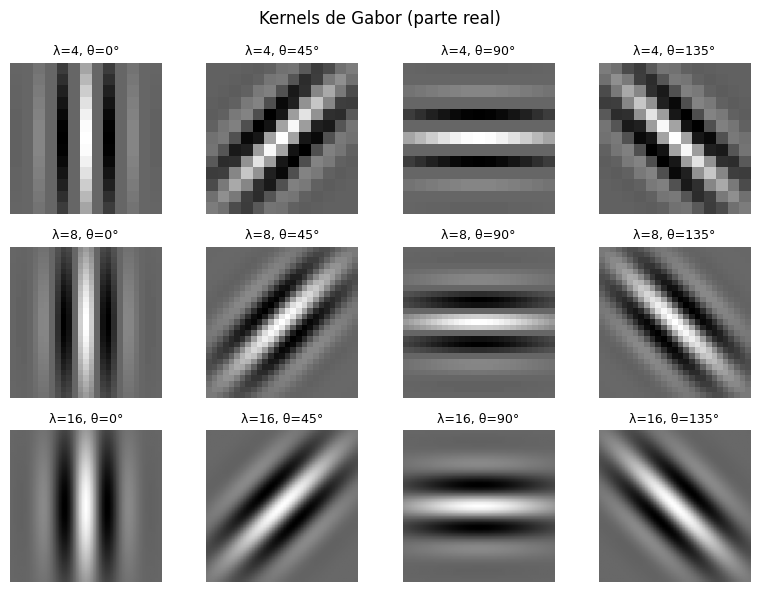

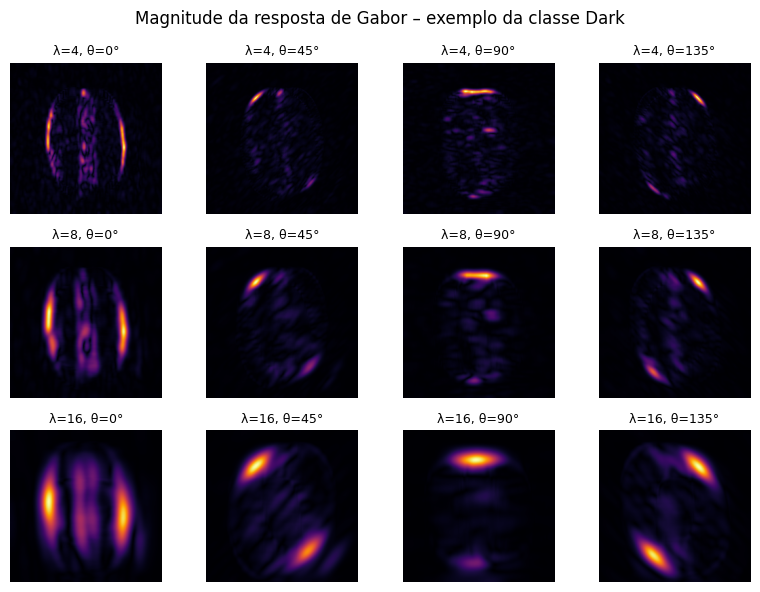

Nº de características Gabor: 24


In [7]:
def criar_banco_gabor():
    banco = []
    for lambd in GABOR_COMPRIMENTOS_ONDA:
        sigma = 0.56 * lambd
        ksize = int(6 * sigma) | 1
        for i in range(GABOR_ORIENTACOES):
            theta = i * np.pi / GABOR_ORIENTACOES
            real = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, GABOR_GAMMA, 0, ktype=cv2.CV_32F)
            imag = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, GABOR_GAMMA, np.pi / 2, ktype=cv2.CV_32F)
            real -= real.mean()
            real /= np.abs(real).sum(); imag /= np.abs(imag).sum()
            banco.append((lambd, theta, real, imag))
    return banco

BANCO_GABOR = criar_banco_gabor()

def respostas_gabor(img_cinza):
    f = img_cinza.astype(np.float32) / 255.0
    for _, _, kr, ki in BANCO_GABOR:
        yield cv2.magnitude(cv2.filter2D(f, cv2.CV_32F, kr), cv2.filter2D(f, cv2.CV_32F, ki))

def extrair_gabor(img_cinza):
    feats = []
    for mag in respostas_gabor(img_cinza):
        feats += [mag.mean(), mag.std()]
    return np.array(feats, dtype=np.float32)

NOMES_GABOR = [f"Gabor λ={l} θ={int(np.degrees(t))}° {estat}"
               for l, t, _, _ in BANCO_GABOR for estat in ["média", "desvio"]]

fig, ax = plt.subplots(len(GABOR_COMPRIMENTOS_ONDA), GABOR_ORIENTACOES, figsize=(8, 6))
for n, (l, t, kr, _) in enumerate(BANCO_GABOR):
    a = ax[n // GABOR_ORIENTACOES, n % GABOR_ORIENTACOES]
    a.imshow(kr, cmap="gray"); a.set_title(f"λ={l}, θ={int(np.degrees(t))}°", fontsize=9); a.axis("off")
plt.suptitle("Kernels de Gabor (parte real)"); plt.tight_layout(); plt.show()

exemplo = cv2.cvtColor(imagens_treino[0], cv2.COLOR_RGB2GRAY)
fig, ax = plt.subplots(len(GABOR_COMPRIMENTOS_ONDA), GABOR_ORIENTACOES, figsize=(8, 6))
for n, mag in enumerate(respostas_gabor(exemplo)):
    l, t = BANCO_GABOR[n][:2]
    a = ax[n // GABOR_ORIENTACOES, n % GABOR_ORIENTACOES]
    a.imshow(mag, cmap="inferno"); a.set_title(f"λ={l}, θ={int(np.degrees(t))}°", fontsize=9); a.axis("off")
plt.suptitle(f"Magnitude da resposta de Gabor – exemplo da classe {rotulos_treino[0]}"); plt.tight_layout(); plt.show()
print("Nº de características Gabor:", len(extrair_gabor(exemplo)))

## 7. Descritor 3 – Momentos de cor (Stricker & Orengo, 1995)
O nível de torra muda principalmente a **cor** do grão. Em vez de um histograma de cor (visto em aula), resumimos a
distribuição de cada canal pelos seus **três primeiros momentos**: média, desvio padrão e assimetria (raiz cúbica do 3º momento central).

Canais usados: **L\*, a\*, b\*** (espaço Lab, perceptualmente uniforme) e **S, V** (espaço HSV).
O canal H não é usado por ser circular (0° = 360°), o que distorce média e assimetria. Total: 5 × 3 = **15 características**.

In [8]:
def momentos_canal(canal):
    c = canal.astype(np.float32).ravel()
    media, desvio = c.mean(), c.std()
    assimetria = np.cbrt(np.mean((c - media) ** 3))
    return [media, desvio, assimetria]

def extrair_momentos_cor(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    canais = [lab[..., 0], lab[..., 1], lab[..., 2], hsv[..., 1], hsv[..., 2]]
    feats = []
    for canal in canais:
        feats += momentos_canal(canal)
    return np.array(feats, dtype=np.float32)

NOMES_COR = [f"Cor {c} {m}" for c in ["L*", "a*", "b*", "S", "V"] for m in ["média", "desvio", "assimetria"]]
print("Nº de características de cor:", len(extrair_momentos_cor(imagens_treino[0])))

Nº de características de cor: 15


## 8. Extração das características de todas as imagens
O vetor final de cada imagem é a concatenação **GLCM (42) + Gabor (24) + Cor (15) = 81 características**.
As características são salvas em `caracteristicas.npz` (equivalente à pasta `features/` do projeto da aula).

In [9]:
BLOCOS = ["GLCM", "Gabor", "Cor"]
NOMES_CARACTERISTICAS = NOMES_GLCM + NOMES_GABOR + NOMES_COR

def extrair_caracteristicas(imagens, desc):
    blocos = {b: [] for b in BLOCOS}
    for img in tqdm(imagens, desc=desc):
        cinza = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        blocos["GLCM"].append(extrair_glcm(cinza))
        blocos["Gabor"].append(extrair_gabor(cinza))
        blocos["Cor"].append(extrair_momentos_cor(img))
    return {b: np.nan_to_num(np.vstack(v)) for b, v in blocos.items()}

t0 = time.time()
F_treino = extrair_caracteristicas(imagens_treino, "Extraindo características (treino)")
F_teste  = extrair_caracteristicas(imagens_teste,  "Extraindo características (teste)")
print(f"Extração concluída em {time.time() - t0:.1f}s")

X_treino = np.hstack([F_treino[b] for b in BLOCOS])
X_teste  = np.hstack([F_teste[b]  for b in BLOCOS])
assert X_treino.shape[1] == len(NOMES_CARACTERISTICAS)
for b in BLOCOS:
    print(f"{b:6s}: {F_treino[b].shape[1]} características")
print("X_treino:", X_treino.shape, "| X_teste:", X_teste.shape)

np.savez_compressed("caracteristicas.npz", X_treino=X_treino, y_treino=y_treino,
                    X_teste=X_teste, y_teste=y_teste, nomes=np.array(NOMES_CARACTERISTICAS), classes=np.array(CLASSES))

Extraindo características (treino):   0%|          | 0/1200 [00:00<?, ?it/s]

Extraindo características (teste):   0%|          | 0/400 [00:00<?, ?it/s]

Extração concluída em 110.3s
GLCM  : 42 características
Gabor : 24 características
Cor   : 15 características
X_treino: (1200, 81) | X_teste: (400, 81)


## 9. Contribuição de cada descritor (validação cruzada no treino)
Antes do treino final, compara-se cada descritor isolado e combinado com um SVM RBF, usando **validação cruzada de 5 folds
somente no conjunto de treino** (o teste não é usado aqui). O `StandardScaler` fica dentro do `Pipeline`, então
a normalização é ajustada apenas nos folds de treino (sem vazamento de dados).

In [10]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
combinacoes = {
    "GLCM": ["GLCM"],
    "Gabor": ["Gabor"],
    "Momentos de cor": ["Cor"],
    "GLCM + Gabor (só textura)": ["GLCM", "Gabor"],
    "GLCM + Gabor + Cor": BLOCOS,
}
linhas = []
for nome, bl in combinacoes.items():
    X = np.hstack([F_treino[b] for b in bl])
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", C=10, gamma="scale"))])
    s = cross_val_score(pipe, X, y_treino, cv=cv, scoring="accuracy", n_jobs=-1)
    linhas.append({"Descritores": nome, "Nº de características": X.shape[1],
                   "Acurácia CV (média)": s.mean(), "Desvio padrão": s.std()})
df_ablacao = pd.DataFrame(linhas)
display(df_ablacao.style.format({"Acurácia CV (média)": "{:.4f}", "Desvio padrão": "{:.4f}"}).hide(axis="index"))

Descritores,Nº de características,Acurácia CV (média),Desvio padrão
GLCM,42,0.8517,0.0131
Gabor,24,0.8258,0.0198
Momentos de cor,15,0.9933,0.0077
GLCM + Gabor (só textura),66,0.8975,0.0122
GLCM + Gabor + Cor,81,0.9917,0.0046


## 10. Treinamento dos classificadores (SVM e Random Forest)
Diferente do código da aula (hiperparâmetros fixos: SVM linear com C=1, Random Forest com 100 árvores), os hiperparâmetros
são escolhidos por **`GridSearchCV`** com validação cruzada estratificada de 5 folds no treino.
O modelo final é escolhido pela **melhor acurácia na validação cruzada**, e não pelo teste.

In [11]:
modelos = {
    "SVM (RBF)": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=SEED))]),
        {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]},
    ),
    "Random Forest": (
        Pipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(random_state=SEED))]),
        {"clf__n_estimators": [300, 600], "clf__max_depth": [None, 20], "clf__max_features": ["sqrt", 0.3]},
    ),
}

buscas = {}
for nome, (pipe, grade) in modelos.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grade, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_treino, y_treino)
    buscas[nome] = gs
    print(f"{nome:14s} | acurácia CV = {gs.best_score_:.4f} | {gs.best_params_} | {time.time() - t0:.1f}s")

MELHOR = max(buscas, key=lambda n: buscas[n].best_score_)
print("\nModelo escolhido pela validação cruzada:", MELHOR)

SVM (RBF)      | acurácia CV = 0.9933 | {'clf__C': 100, 'clf__gamma': 0.01} | 1.8s
Random Forest  | acurácia CV = 0.9858 | {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__n_estimators': 300} | 156.7s

Modelo escolhido pela validação cruzada: SVM (RBF)


## 11. Avaliação no conjunto de TESTE

In [12]:
def calcular_metricas(y_true, y_pred):
    return {"Acurácia": accuracy_score(y_true, y_pred),
            "Precisão (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "F1-score (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0)}

predicoes = {nome: gs.predict(X_teste) for nome, gs in buscas.items()}
df_resultados = pd.DataFrame({nome: calcular_metricas(y_teste, p) for nome, p in predicoes.items()}).T
display(df_resultados.style.format("{:.4f}").highlight_max(axis=0, color="#cde4f7"))

for nome, p in predicoes.items():
    print(f"\n===== Relatório por classe – {nome}{'  (modelo escolhido)' if nome == MELHOR else ''} =====\n")
    print(classification_report(y_teste, p, target_names=CLASSES, digits=4, zero_division=0))

,Acurácia,Precisão (macro),Recall (macro),F1-score (macro)
SVM (RBF),1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000



===== Relatório por classe – SVM (RBF)  (modelo escolhido) =====

              precision    recall  f1-score   support

        Dark     1.0000    1.0000    1.0000       100
       Green     1.0000    1.0000    1.0000       100
       Light     1.0000    1.0000    1.0000       100
      Medium     1.0000    1.0000    1.0000       100

    accuracy                         1.0000       400
   macro avg     1.0000    1.0000    1.0000       400
weighted avg     1.0000    1.0000    1.0000       400


===== Relatório por classe – Random Forest =====

              precision    recall  f1-score   support

        Dark     1.0000    1.0000    1.0000       100
       Green     1.0000    1.0000    1.0000       100
       Light     1.0000    1.0000    1.0000       100
      Medium     1.0000    1.0000    1.0000       100

    accuracy                         1.0000       400
   macro avg     1.0000    1.0000    1.0000       400
weighted avg     1.0000    1.0000    1.0000       400



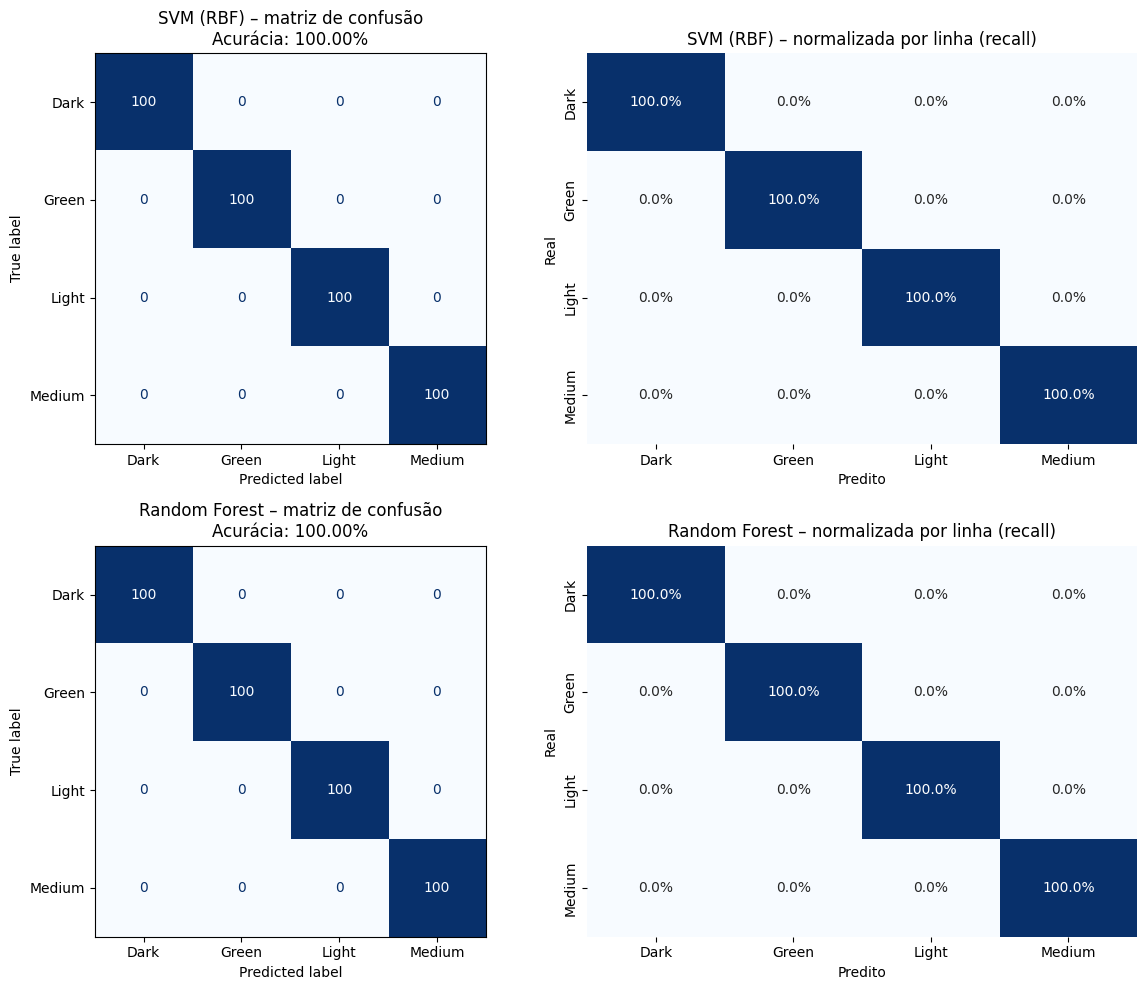

In [13]:
fig, ax = plt.subplots(len(predicoes), 2, figsize=(12, 5 * len(predicoes)))
for i, (nome, p) in enumerate(predicoes.items()):
    cm = confusion_matrix(y_teste, p)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[i, 0], cmap="Blues", colorbar=False)
    ax[i, 0].set_title(f"{nome} – matriz de confusão\nAcurácia: {accuracy_score(y_teste, p):.2%}")
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".1%", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[i, 1], cbar=False)
    ax[i, 1].set_title(f"{nome} – normalizada por linha (recall)")
    ax[i, 1].set_xlabel("Predito"); ax[i, 1].set_ylabel("Real")
plt.tight_layout(); plt.show()

## 12. Características mais importantes (Random Forest)

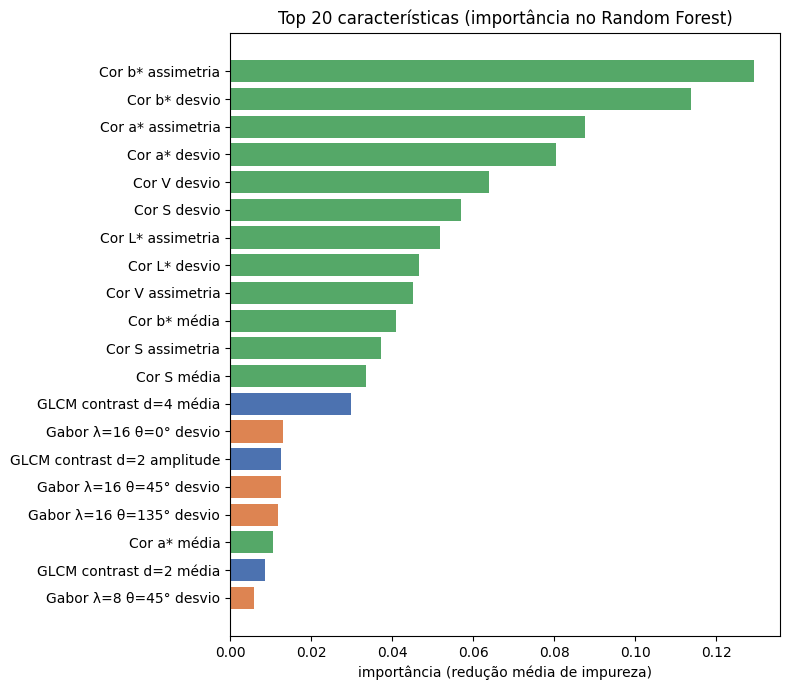

Importância total por descritor:
Cor      0.802
GLCM     0.115
Gabor    0.083


In [14]:
rf = buscas["Random Forest"].best_estimator_.named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=NOMES_CARACTERISTICAS).sort_values(ascending=False)
cores = {"GLCM": "#4C72B0", "Gabor": "#DD8452", "Cor": "#55A868"}
top = imp.head(20)[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=[cores[n.split()[0]] for n in top.index])
plt.title("Top 20 características (importância no Random Forest)")
plt.xlabel("importância (redução média de impureza)")
plt.tight_layout(); plt.show()

print("Importância total por descritor:")
print(imp.groupby(lambda n: n.split()[0]).sum().sort_values(ascending=False).round(3).to_string())

## 13. Exemplos de predições do modelo escolhido (erros em vermelho)

SVM (RBF): 0 erros de 400 imagens de teste


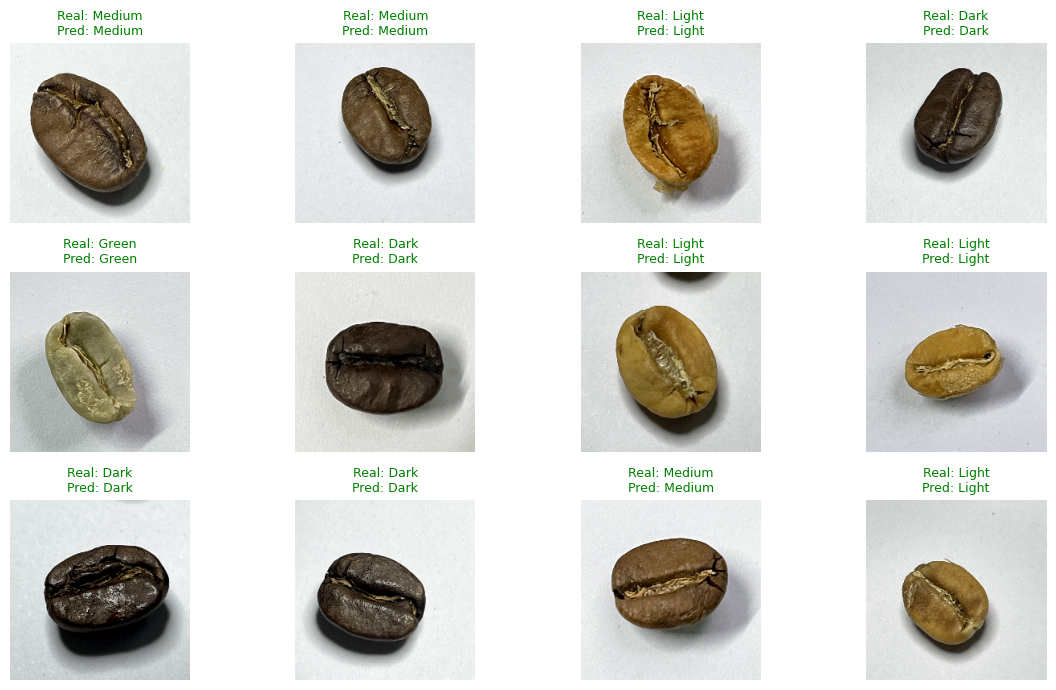

In [15]:
y_pred = predicoes[MELHOR]
erros = np.where(y_pred != y_teste)[0]
acertos = np.where(y_pred == y_teste)[0]
print(f"{MELHOR}: {len(erros)} erros de {len(y_teste)} imagens de teste")
n_err = min(6, len(erros))
idx = list(erros[:n_err]) + list(np.random.choice(acertos, 12 - n_err, replace=False))
plt.figure(figsize=(12, 7))
for i, k in enumerate(idx):
    plt.subplot(3, 4, i + 1); plt.imshow(imagens_teste[k]); plt.axis("off")
    ok = y_pred[k] == y_teste[k]
    plt.title(f"Real: {CLASSES[y_teste[k]]}\nPred: {CLASSES[y_pred[k]]}", color="green" if ok else "red", fontsize=9)
plt.tight_layout(); plt.show()

## 14. Salvando modelo e resultados

In [16]:
import joblib
joblib.dump(buscas[MELHOR].best_estimator_, "modelo_final.joblib")

resultados = {
    "abordagem": "Clássica: GLCM (Haralick) + Gabor + Momentos de cor",
    "classes": CLASSES,
    "n_caracteristicas": int(X_treino.shape[1]),
    "modelo_escolhido": MELHOR,
    "melhores_hiperparametros": {n: {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                                     for k, v in gs.best_params_.items()} for n, gs in buscas.items()},
    "metricas_teste": {n: {k: round(float(v), 4) for k, v in m.items()} for n, m in df_resultados.T.to_dict().items()},
    "matriz_confusao": {n: confusion_matrix(y_teste, p).tolist() for n, p in predicoes.items()},
}
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)
print(open("resultados.json", encoding="utf-8").read())

{
  "abordagem": "Clássica: GLCM (Haralick) + Gabor + Momentos de cor",
  "classes": [
    "Dark",
    "Green",
    "Light",
    "Medium"
  ],
  "n_caracteristicas": 81,
  "modelo_escolhido": "SVM (RBF)",
  "melhores_hiperparametros": {
    "SVM (RBF)": {
      "clf__C": 100,
      "clf__gamma": 0.01
    },
    "Random Forest": {
      "clf__max_depth": null,
      "clf__max_features": "sqrt",
      "clf__n_estimators": 300
    }
  },
  "metricas_teste": {
    "SVM (RBF)": {
      "Acurácia": 1.0,
      "Precisão (macro)": 1.0,
      "Recall (macro)": 1.0,
      "F1-score (macro)": 1.0
    },
    "Random Forest": {
      "Acurácia": 1.0,
      "Precisão (macro)": 1.0,
      "Recall (macro)": 1.0,
      "F1-score (macro)": 1.0
    }
  },
  "matriz_confusao": {
    "SVM (RBF)": [
      [
        100,
        0,
        0,
        0
      ],
      [
        0,
        100,
        0,
        0
      ],
      [
        0,
        0,
        100,
        0
      ],
      [
        0,
      